<center><h1>Лабораторная работа № 9</h1></center>

---

## **Тема:** Контурный анализ

**Цель работы** — освоить обнаружение границ и контуров на фотографиях с помощью OpenCV, научиться определять внешние контуры, находить окружности, измерять контуры и подсчитывать геометрические формы.

Работа включает четыре части:
1. Сравнение операторов Собеля, Лапласа и детектора границ Кэнни.
2. Поиск контуров предметов, ограничивающие прямоугольники, число объектов, периметры и площади; сохранение объектов в отдельные файлы.
3. Поиск круглых объектов с помощью `cv2.HoughCircles()`.
4. Подсчёт прямоугольных или треугольных форм на фотографии.

**Важное требование методички:** использовать только фотографии реального мира. В проект включены реальные фотографии из демонстрационных данных `scikit-image`, а не нарисованные программно фигуры. Для наиболее соответствующего заданию результата замените образцы собственными фотографиями, сделанными телефоном.

In [10]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def locate_image_dir():
    for base in [Path.cwd(), *Path.cwd().parents]:
        candidate = base / "Lab9_images"
        if candidate.is_dir():
            return candidate
    return Path("Lab9_images")

IMAGE_DIR = locate_image_dir()
PROJECT_DIR = IMAGE_DIR.parent if IMAGE_DIR.exists() else Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "Lab9_output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def load_photo(kind, fallback_name):
    """Загружает реальное пользовательское фото my_<kind> или фото из комплекта."""
    for extension in ("jpg", "jpeg", "png", "JPG", "JPEG", "PNG"):
        candidate = IMAGE_DIR / f"my_{kind}.{extension}"
        if candidate.exists():
            image = cv2.imread(str(candidate), cv2.IMREAD_COLOR)
            if image is not None:
                return image, candidate.name, True
    fallback_path = IMAGE_DIR / fallback_name
    image = cv2.imread(str(fallback_path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(
            f"Не удалось загрузить {fallback_path}. Убедитесь, что папка Lab9_images находится рядом с ноутбуком."
        )
    return image, fallback_path.name, False


def show_bgr(ax, image, title):
    """Показывает изображение OpenCV в правильном цветовом порядке для matplotlib."""
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")


edges_bgr, edges_name, edges_custom = load_photo("edges", "camera.jpg")
objects_bgr, objects_name, objects_custom = load_photo("objects", "coins.jpg")
circles_bgr, circles_name, circles_custom = load_photo("circles", "coins.jpg")
shapes_bgr, shapes_name, shapes_custom = load_photo("shapes", "brick.jpg")

print("OpenCV:", cv2.__version__)
print("Папка с изображениями:", IMAGE_DIR.resolve())
for task, name, image, custom in [
    ("Границы", edges_name, edges_bgr, edges_custom),
    ("Контуры предметов", objects_name, objects_bgr, objects_custom),
    ("Окружности", circles_name, circles_bgr, circles_custom),
    ("Геометрические формы", shapes_name, shapes_bgr, shapes_custom),
]:
    print(f"{task}: {name}; размер {image.shape[1]}×{image.shape[0]}; " + ("собственное фото" if custom else "фото из комплекта"))



OpenCV: 5.0.0
Папка с изображениями: /home/litvinas/git/BSTU/4/1/Интеллектуальная обработка и анализ данных/9/Lab9_images
Границы: camera.jpg; размер 512×512; фото из комплекта
Контуры предметов: coins.jpg; размер 384×303; фото из комплекта
Окружности: coins.jpg; размер 384×303; фото из комплекта
Геометрические формы: brick.jpg; размер 512×512; фото из комплекта


## 1. Операторы Собеля, Лапласа и детектор Кэнни

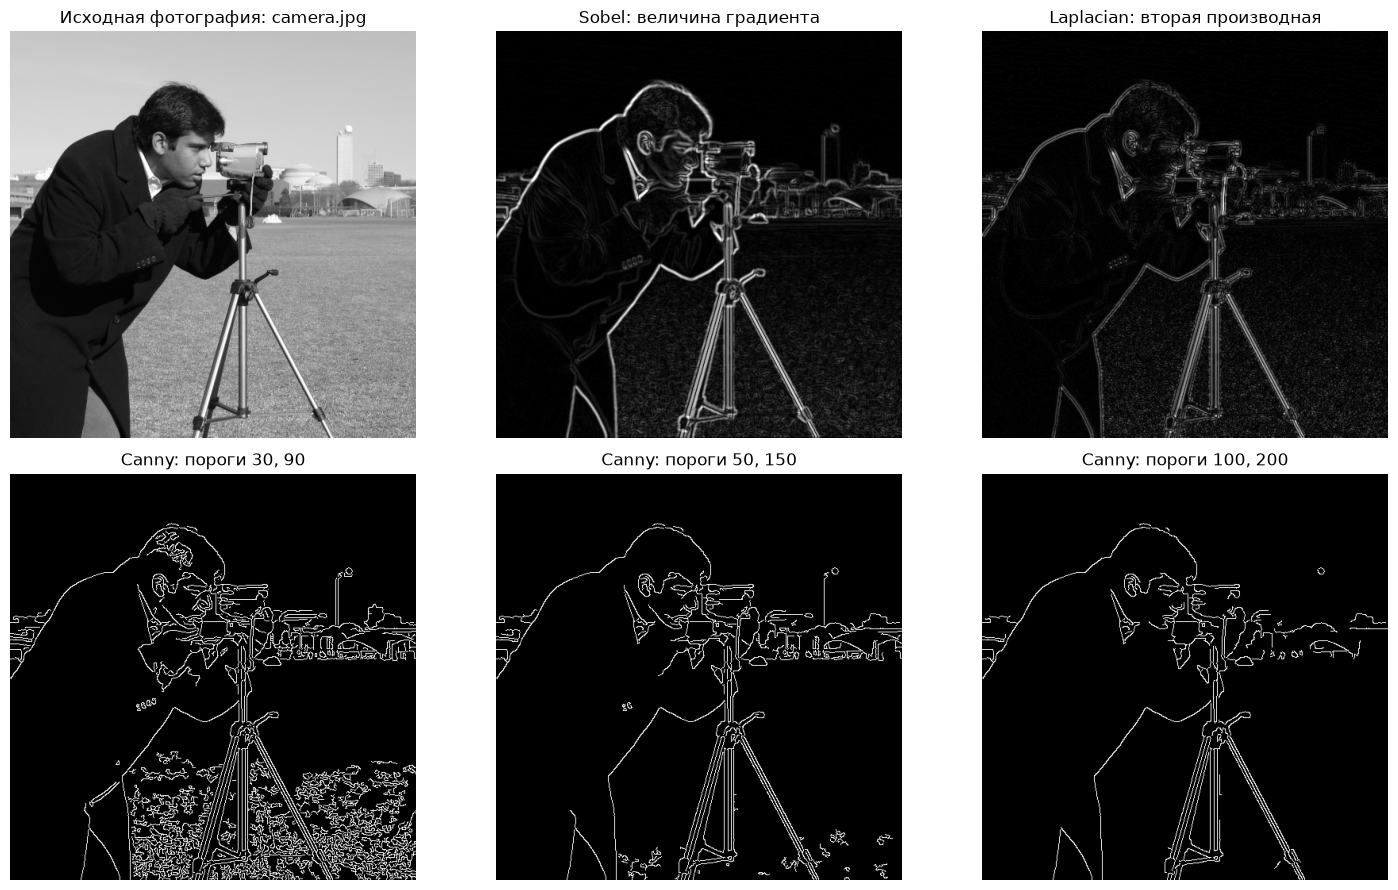

Выбранные пороги Canny: threshold1=50, threshold2=150
Плотность найденных пикселей границ: 3.45%


In [ ]:
edges_gray = cv2.cvtColor(edges_bgr, cv2.COLOR_BGR2GRAY)
edges_blurred = cv2.GaussianBlur(edges_gray, (5, 5), 0)

# Собель: градиенты по X и Y.
sobel_x = cv2.Sobel(edges_blurred, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(edges_blurred, cv2.CV_64F, 0, 1, ksize=3)
sobel_x_abs = cv2.convertScaleAbs(sobel_x)
sobel_y_abs = cv2.convertScaleAbs(sobel_y)
sobel_magnitude = cv2.addWeighted(sobel_x_abs, 0.5, sobel_y_abs, 0.5, 0)

# Лаплас: вторая производная.
laplacian = cv2.Laplacian(edges_blurred, cv2.CV_64F, ksize=3)
laplacian_abs = cv2.convertScaleAbs(laplacian)

# Сравним три пары порогов Кэнни, а затем выберем используемую пару.
canny_trials = [(30, 90), (50, 150), (100, 200)]
canny_trial_images = [cv2.Canny(edges_blurred, low, high) for low, high in canny_trials]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
show_bgr(axes[0, 0], edges_bgr, f"Исходная фотография: {edges_name}")
axes[0, 1].imshow(sobel_magnitude, cmap="gray")
axes[0, 1].set_title("Sobel: величина градиента")
axes[0, 1].axis("off")
axes[0, 2].imshow(laplacian_abs, cmap="gray")
axes[0, 2].set_title("Laplacian: вторая производная")
axes[0, 2].axis("off")
for ax, image, (low, high) in zip(axes[1], canny_trial_images, canny_trials):
    ax.imshow(image, cmap="gray")
    ax.set_title(f"Canny: пороги {low}, {high}")
    ax.axis("off")
plt.tight_layout()
plt.show()

canny_low, canny_high = 50, 150
canny_edges = cv2.Canny(edges_blurred, canny_low, canny_high)
print(f"Выбранные пороги Canny: threshold1={canny_low}, threshold2={canny_high}")
print("Плотность найденных пикселей границ: {:.2%}".format(np.count_nonzero(canny_edges) / canny_edges.size))

## 2. Поиск контуров объектов, прямоугольники, площадь, периметр и сохранение предметов



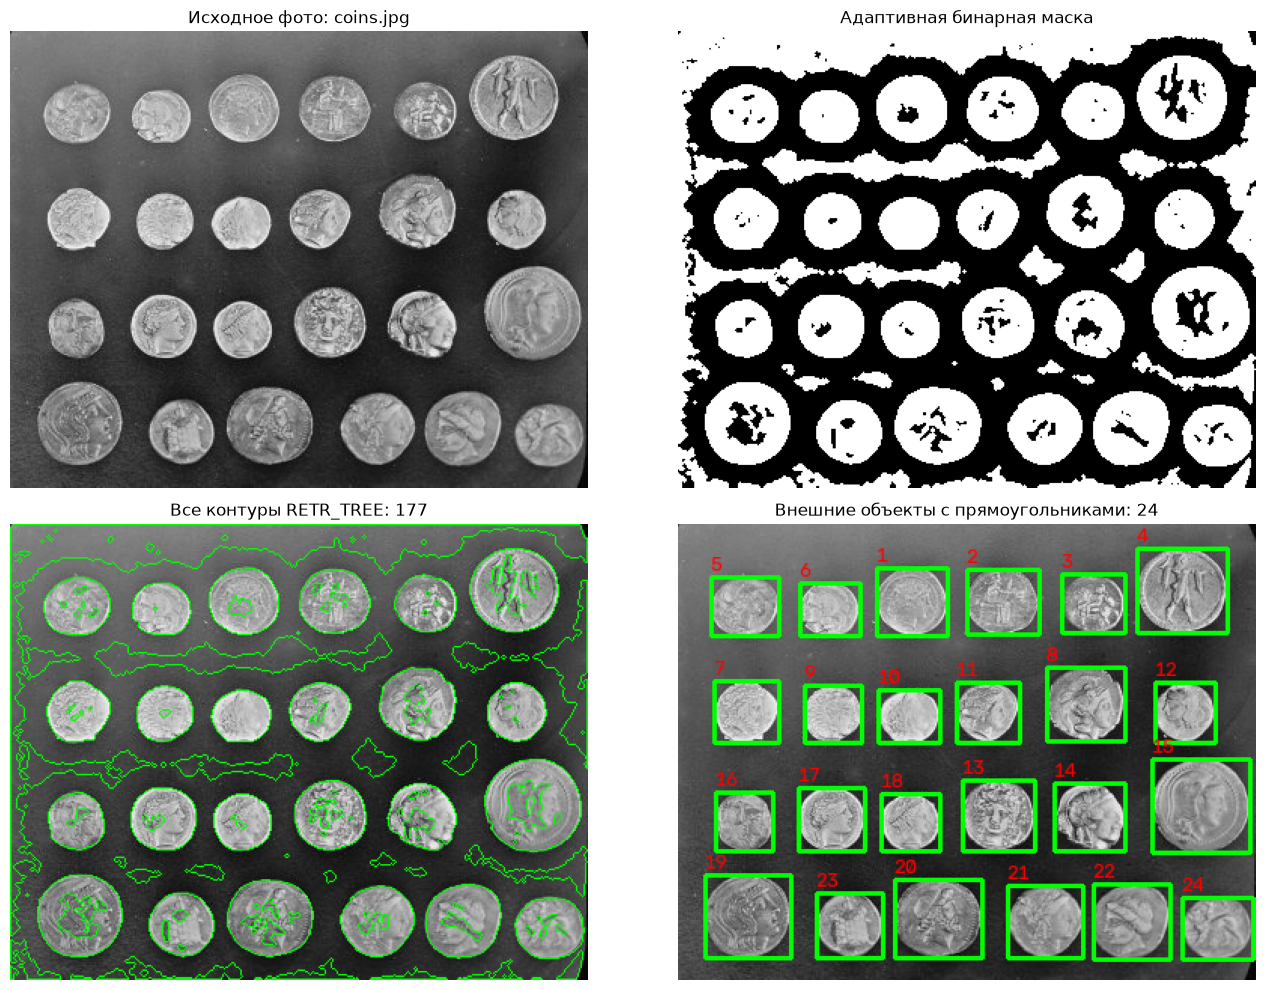

Количество всех найденных контуров: 177
Количество внешних контуров до фильтра площади: 57
Количество объектов после фильтрации: 24
Порог минимальной площади: 500 пикселей²


,Объект,X,Y,Ширина,Высота,"Периметр контура, px","Площадь контура, px²",Файл
0,1,132,29,47,45,151.54,1626.0,object_01.png
1,2,192,30,48,43,149.30,1579.5,object_02.png
2,3,255,33,42,39,131.64,1202.5,object_03.png
3,4,305,16,60,56,189.92,2570.5,object_04.png
4,5,22,35,45,39,136.47,1330.5,object_05.png
5,6,81,39,40,35,123.74,1078.0,object_06.png
6,7,24,104,43,41,135.88,1298.0,object_07.png
7,8,245,95,52,49,165.20,1894.0,object_08.png
8,9,84,107,38,38,123.98,1087.5,object_09.png
9,10,133,110,41,35,123.40,1074.0,object_10.png



Кропы сохранены в папке: /home/litvinas/git/BSTU/4/1/Интеллектуальная обработка и анализ данных/9/Lab9_output


In [12]:
objects_gray = cv2.cvtColor(objects_bgr, cv2.COLOR_BGR2GRAY)
objects_blurred = cv2.GaussianBlur(objects_gray, (5, 5), 0)

# Адаптивная бинаризация лучше справляется с небольшими перепадами освещения на фотографии.
object_mask = cv2.adaptiveThreshold(
    objects_blurred, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
    cv2.THRESH_BINARY, 31, 3
)

# Морфологическое открытие убирает мелкие белые точки.
object_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
object_mask_clean = cv2.morphologyEx(object_mask, cv2.MORPH_OPEN, object_kernel)

# Все контуры с иерархией и только внешние контуры.
contours_all, hierarchy_all = cv2.findContours(
    object_mask_clean.copy(), cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE
)
contours_external, hierarchy_external = cv2.findContours(
    object_mask_clean.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

# Удаляем крошечные фрагменты. Для фото монет добавляем ограничение формы/размера,
# чтобы не считать тёмные текстурные фрагменты фона самостоятельными объектами.
MIN_OBJECT_AREA = 500 if (objects_name == "coins.jpg" and not objects_custom) else 600
object_contours = []
for contour in contours_external:
    area = cv2.contourArea(contour)
    if area < MIN_OBJECT_AREA:
        continue
    if objects_name == "coins.jpg" and not objects_custom:
        x, y, w, h = cv2.boundingRect(contour)
        aspect_ratio = w / max(h, 1)
        if not (20 <= w <= 75 and 20 <= h <= 75 and 0.65 < aspect_ratio < 1.5):
            continue
    object_contours.append(contour)
object_contours.sort(key=lambda c: (cv2.boundingRect(c)[1] // 35, cv2.boundingRect(c)[0]))

all_contours_view = cv2.drawContours(objects_bgr.copy(), contours_all, -1, (0, 255, 0), 1)
external_view = objects_bgr.copy()
records = []

# Очищаем старые кропы из предыдущего запуска.
for old_file in OUTPUT_DIR.glob("object_*.png"):
    old_file.unlink()

for index, contour in enumerate(object_contours, start=1):
    x, y, w, h = cv2.boundingRect(contour)
    area = cv2.contourArea(contour)
    perimeter = cv2.arcLength(contour, True)
    cv2.rectangle(external_view, (x, y), (x + w, y + h), (0, 255, 0), 2)
    cv2.putText(external_view, str(index), (x, max(12, y - 4)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 255), 1, cv2.LINE_AA)
    crop = objects_bgr[y:y+h, x:x+w]
    crop_path = OUTPUT_DIR / f"object_{index:02d}.png"
    cv2.imwrite(str(crop_path), crop)
    records.append({
        "Объект": index,
        "X": x, "Y": y, "Ширина": w, "Высота": h,
        "Периметр контура, px": round(perimeter, 2),
        "Площадь контура, px²": round(area, 2),
        "Файл": crop_path.name,
    })

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
show_bgr(axes[0, 0], objects_bgr, f"Исходное фото: {objects_name}")
axes[0, 1].imshow(object_mask_clean, cmap="gray")
axes[0, 1].set_title("Адаптивная бинарная маска")
axes[0, 1].axis("off")
show_bgr(axes[1, 0], all_contours_view, f"Все контуры RETR_TREE: {len(contours_all)}")
show_bgr(axes[1, 1], external_view, f"Внешние объекты с прямоугольниками: {len(object_contours)}")
plt.tight_layout()
plt.show()

print("Количество всех найденных контуров:", len(contours_all))
print("Количество внешних контуров до фильтра площади:", len(contours_external))
print("Количество объектов после фильтрации:", len(object_contours))
print("Порог минимальной площади:", MIN_OBJECT_AREA, "пикселей²")
display(pd.DataFrame(records))
print(f"\nКропы сохранены в папке: {OUTPUT_DIR.resolve()}")

## 3. Поиск окружностей с помощью `cv2.HoughCircles()`

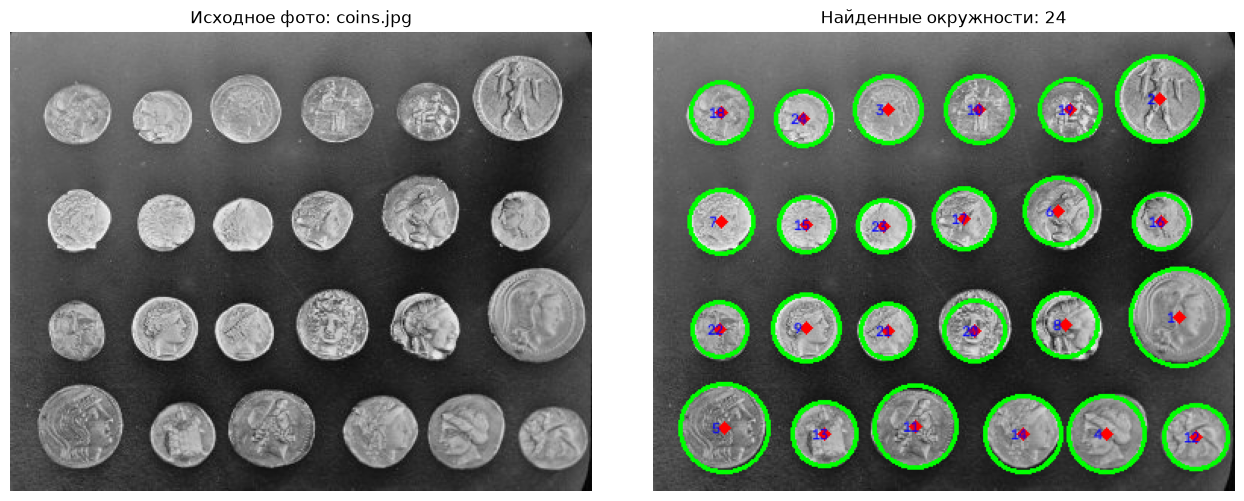

Количество найденных окружностей: 24


In [13]:
circles_gray = cv2.cvtColor(circles_bgr, cv2.COLOR_BGR2GRAY)
circles_blurred = cv2.medianBlur(circles_gray, 5)

# Настройки подобраны для фото coins.jpg. Для собственного снимка может потребоваться изменить радиусы и param2.
circles = cv2.HoughCircles(
    circles_blurred,
    cv2.HOUGH_GRADIENT,
    dp=1.2,
    minDist=30,
    param1=100,
    param2=28,
    minRadius=12,
    maxRadius=40,
)

circles_view = circles_bgr.copy()
if circles is not None:
    circles = np.uint16(np.around(circles[0]))
    for index, (x, y, radius) in enumerate(circles, start=1):
        cv2.circle(circles_view, (x, y), radius, (0, 255, 0), 2)
        cv2.circle(circles_view, (x, y), 2, (0, 0, 255), 3)
        cv2.putText(circles_view, str(index), (x - 8, y + 4),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.35, (255, 0, 0), 1, cv2.LINE_AA)
    circle_count = len(circles)
else:
    circle_count = 0

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
show_bgr(axes[0], circles_bgr, f"Исходное фото: {circles_name}")
show_bgr(axes[1], circles_view, f"Найденные окружности: {circle_count}")
plt.tight_layout()
plt.show()
print("Количество найденных окружностей:", circle_count)

## 4. Подсчёт прямоугольников или треугольников на фотографии

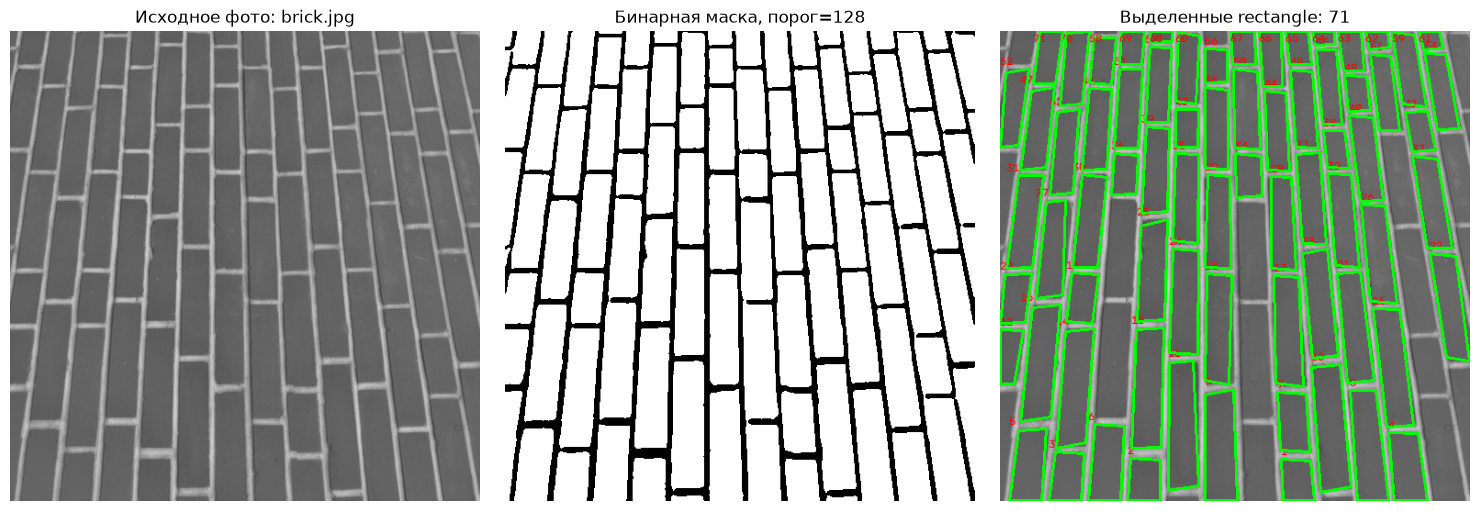

Количество найденных rectangle: 71
Источник фото: brick.jpg
Примечание: результат зависит от фона, перспективы, освещения и выбранных порогов.


In [ ]:

SHAPE_TO_COUNT = "rectangle"
MIN_SHAPE_AREA = 250

shapes_gray = cv2.cvtColor(shapes_bgr, cv2.COLOR_BGR2GRAY)
shapes_blurred = cv2.GaussianBlur(shapes_gray, (5, 5), 0)
shape_threshold, shapes_binary = cv2.threshold(
    shapes_blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)
shape_contours, shape_hierarchy = cv2.findContours(
    shapes_binary.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)


def max_abs_corner_cosine(approx):
    """Возвращает максимальный |cos(angle)| среди углов многоугольника."""
    points = approx.reshape(-1, 2).astype(float)
    cosines = []
    for i in range(len(points)):
        p_prev = points[i - 1]
        p = points[i]
        p_next = points[(i + 1) % len(points)]
        v1 = p_prev - p
        v2 = p_next - p
        denominator = np.linalg.norm(v1) * np.linalg.norm(v2)
        if denominator == 0:
            return 1.0
        cosines.append(abs(float(np.dot(v1, v2) / denominator)))
    return max(cosines, default=1.0)


def is_rectangle_like(approx):
    return len(approx) == 4 and cv2.isContourConvex(approx) and max_abs_corner_cosine(approx) < 0.35

shape_candidates = []
for contour in shape_contours:
    area = cv2.contourArea(contour)
    if area < MIN_SHAPE_AREA:
        continue
    perimeter = cv2.arcLength(contour, True)
    if perimeter <= 0:
        continue
    approx = cv2.approxPolyDP(contour, 0.03 * perimeter, True)
    if not cv2.isContourConvex(approx):
        continue
    if SHAPE_TO_COUNT == "rectangle":
        accepted = is_rectangle_like(approx)
    elif SHAPE_TO_COUNT == "triangle":
        accepted = len(approx) == 3
    else:
        raise ValueError('SHAPE_TO_COUNT должен быть "rectangle" или "triangle"')
    if accepted:
        shape_candidates.append((contour, approx, area))

shapes_view = shapes_bgr.copy()
for index, (contour, approx, area) in enumerate(shape_candidates, start=1):
    cv2.drawContours(shapes_view, [approx], -1, (0, 255, 0), 2)
    x, y, w, h = cv2.boundingRect(approx)
    cv2.putText(shapes_view, str(index), (x, max(12, y - 4)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 0, 255), 1, cv2.LINE_AA)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
show_bgr(axes[0], shapes_bgr, f"Исходное фото: {shapes_name}")
axes[1].imshow(shapes_binary, cmap="gray")
axes[1].set_title(f"Бинарная маска, порог={shape_threshold:.0f}")
axes[1].axis("off")
show_bgr(axes[2], shapes_view, f"Выделенные {SHAPE_TO_COUNT}: {len(shape_candidates)}")
plt.tight_layout()
plt.show()
print(f"Количество найденных {SHAPE_TO_COUNT}: {len(shape_candidates)}")
print("Источник фото:", shapes_name)
print("Примечание: результат зависит от фона, перспективы, освещения и выбранных порогов.")

# Контрольные вопросы

## 1. Какие функции осуществляют поиск границ на изображении?

В этой лабораторной используются три основных метода OpenCV: `cv2.Sobel()`, `cv2.Laplacian()` и `cv2.Canny()`. Собель оценивает первую производную яркости, Лаплас — вторую производную, а Canny реализует многоэтапный алгоритм выделения тонких границ. Перед обнаружением границ часто применяют сглаживание, например `cv2.GaussianBlur()`, чтобы уменьшить влияние шума.

## 2. На чём основан принцип работы оператора Собеля?

Оператор Собеля использует свёртку изображения с небольшими матрицами (ядрами), приближающими производную яркости по горизонтали и вертикали. Результаты `cv2.Sobel(gray, ..., 1, 0)` и `cv2.Sobel(gray, ..., 0, 1)` характеризуют изменение яркости вдоль двух направлений. Большая величина градиента обычно соответствует границе объекта.

## 3. На чём основан принцип работы оператора Лапласа?

Оператор Лапласа использует вторую производную изображения: сумму вторых производных по координатам X и Y. Он реагирует на быстрые изменения яркости независимо от основного направления границы. Поскольку вторая производная чувствительна к шуму, перед применением Лапласа обычно сглаживают изображение. Для отображения результата signed-значения производной преобразуют к видимому диапазону.

## 4. Расскажите алгоритм метода Кэнни.

Типичный алгоритм Canny состоит из этапов:
1. Сглаживание изображения, обычно гауссовым фильтром.
2. Расчёт градиента яркости и его направления.
3. Подавление немаксимумов — утончение границ.
4. Двойная пороговая обработка: выделение сильных и слабых кандидатов на границы.
5. Отслеживание границ по связности (гистерезис): слабые точки сохраняются, если связаны с сильными границами; остальные удаляются.

## 5. Как параметры в функции `cv2.Canny()` влияют на конечный результат?

`threshold1` — нижний порог, `threshold2` — верхний. Градиент выше верхнего порога считается сильной границей, ниже нижнего — отбрасывается, а промежуточные значения сохраняются только при связи с сильной границей. Слишком низкие пороги могут давать много ложных границ и шума; слишком высокие — пропускать слабые детали. Также на результат влияют предварительное сглаживание и само качество изображения. Как правило, верхний порог задают не ниже нижнего.

## 6. В каком виде возвращает контуры функция `cv2.findContours()`?

В OpenCV 4 функция возвращает два объекта: `(contours, hierarchy)`. `contours` — список контуров, каждый из которых является массивом координат точек границы, обычно формы `(N, 1, 2)`. `hierarchy` описывает связи между контурами: следующий, предыдущий, первый дочерний и родительский контур. В старых версиях OpenCV могла возвращаться дополнительная величина, поэтому код для OpenCV 4 обычно распаковывает два результата.

## 7. Чем отличаются результаты работы методов поиска границ (Собель, Кэнни) и методов поиска контуров?

Методы Sobel и Canny вычисляют карту границ — пиксели, где яркость заметно меняется. Результат Canny обычно бинарный и утончённый. `cv2.findContours()` не является оператором границ в том же смысле: он анализирует бинарное изображение и возвращает последовательности точек, образующие границы связных областей, а также иерархию вложенных контуров. На практике перед `findContours()` обычно выполняют бинаризацию или другой шаг, формирующий подходящую маску.

## 8. Как с помощью функции `cv2.findContours()` найти только внешние контуры объектов?

Нужно передать режим `cv2.RETR_EXTERNAL`, например:

```python
contours, hierarchy = cv2.findContours(
    binary_image,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)
```

`RETR_EXTERNAL` возвращает только крайние внешние контуры, без внутренних контуров отверстий и вложенных границ. `cv2.CHAIN_APPROX_SIMPLE` сжимает последовательные участки прямых, сохраняя основные точки контура.